In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 223.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 389.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 391.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 161.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 388.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 407.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 266.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 283.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 209.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 181.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 156.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
import re
import difflib
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import torch
from peft import PeftModel
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer, 
    GenerationConfig
)

2025-12-30 22:23:15.681834: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767133395.872469      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767133395.929038      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-classification-training-v2-0/qwen2.5-1_5b-gencls-lora/"

MAX_NEW_TOKENS = 6
DO_SAMPLE = False

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=False, trust_remote_code=True)
tmpl_path = os.path.join(ADAPTER_DIR, "chat_template.jinja")
if os.path.exists(tmpl_path):
    with open(tmpl_path, "r", encoding="utf-8") as f:
        tokenizer.chat_template = f.read()

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

use_bf16 = torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8
dtype = torch.bfloat16 if use_bf16 else torch.float16

base = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)
model = PeftModel.from_pretrained(base, ADAPTER_DIR)
model.generation_config = GenerationConfig(
    do_sample=False,
    max_new_tokens=MAX_NEW_TOKENS,
    pad_token_id=tokenizer.eos_token_id,
    eos_token_id=tokenizer.eos_token_id,
)
model.eval()
model.config.use_cache = True

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [4]:
all_options = ['Abraham Lincoln', 'Alvy Singer', 'Andrew Detmer', 'Angel', 'Antonio Salieri', 'Benjamin Button', 'Blair Waldorf', 'Bruno Antony', 'Caden Cotard', 'Caesar', 'Coach Eric Taylor', 'Colonel Hans Landa', 'Colonel Nathan R. Jessep', 'Coriolanus', 'D_Artagnan', 'David Aames', 'Doctor Who', 'Dr. Frank-N-Furter', 'Dr. Hannibal Lecter', 'Fletcher Reede', 'Frank T.J. Mackey', 'Fred Flintstone', 'Freddy Krueger', 'Gaston', 'Gregory House', 'HAL 9000', 'Harvey Milk', 'Jack', 'Jack Sparrow', 'Jack Torrance', 'Jackie Moon', 'James Bond', 'James Brown', 'James Carter', 'Jeff Spicoli', 'Jigsaw', 'Jim Morrison', 'John Coffey', 'John Dillinger', 'John Doe', 'John Keating', 'Jordan Belfort', 'Judge Dredd', 'Judy Hoops', 'Juno MacGuff', 'Karl Childers', 'Klaus Mikaelson', 'Leonard Shelby', 'Leroy Jethro Gibbs', 'Lestat de Lioncourt', 'Logan', 'Lucifer Morningstar', 'Lyn Cassady', 'Malcolm X', 'Mark Renton', 'Mary Sibley', 'Mater', 'Michael Scott', 'Murphy MacManus', 'Oliver Queen', 'Pat Solitano', 'Paul Conroy', 'Paul Vitti', 'Peter Parker', 'Po', 'Professor G.H. Dorr', 'Queen Catherine', 'Queen Elizabeth I', 'Rachel Lang', 'Randle McMurphy', 'Raylan Givens', 'Robert Angier', 'Rorschach', 'Seth', 'Sheldon Cooper', 'Sherlock Holmes', 'Shrek', 'Sonny', 'Stanley Ipkiss', 'Stephen Hawking', 'Stifler', 'The Dude', 'Theodore Twombly', 'Thor', 'Tom Ripley', 'Travis Bickle', 'Truman Capote', 'Tugg Speedman', 'Twilight Sparkle', 'Tyler Hawkins', 'Tyrion Lannister', 'Violet Weston', 'Wade Wilson', 'Walt Kowalski', 'Willie Soke']
GLOBAL_RESULTS = {}

In [5]:
SYSTEM_PROMPT = (
    "You are a careful classifier. Choose exactly ONE label from the provided options. "
    "Return ONLY the label text with no extra words."
)

def clean_text(text):
    return str(text).strip()
    
def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)
    
def _norm(s: str) -> str:
    return re.sub(r"\s+", " ", s.strip()).lower()

def pick_from_options(generated: str, options: list[str]) -> str:
    g = _norm(generated)
    norm_opts = [(o, _norm(o)) for o in options]

    for o, on in norm_opts:
        if on == g:
            return o

    token_matches = [
        o for o, on in norm_opts
        if re.search(rf'\b{re.escape(on)}\b', g)
    ]
    if token_matches:
        return max(token_matches, key=lambda x: len(_norm(x)))

    rev_matches = [
        o for o, on in norm_opts
        if g and re.search(rf'\b{re.escape(g)}\b', on)
    ]
    if rev_matches:
        return max(rev_matches, key=lambda x: len(_norm(x)))

    return max(
        options,
        key=lambda o: difflib.SequenceMatcher(None, _norm(o), g).ratio()
    )

def format_prompt(utterance: str, options: list[str]):
    opts_str = ", ".join(options)
    user_content = (
        "Classify the following text by choosing exactly ONE label from the options.\n\n"
        f"Options: {opts_str}\n\n"
        f'Text:\n"""{utterance}"""\n\n'
        "Return ONLY one label from the Options."
    )

    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_content},
    ]

def predict_one(utterance, options):
    messages = format_prompt(utterance, options)

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    gen_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(gen_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    text = re.sub(r'[\s:,\.;\-]+$', '', text)

    return pick_from_options(text, options)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())

    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)

    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    return pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)

def plot_confusion_matrix(df, title_suffix=""):
    labels = sorted(df["role_norm"].unique())
    fig_size_val = max(8, len(labels) * 0.5)
    fig, ax = plt.subplots(figsize=(fig_size_val, fig_size_val))
    label_display_map = df.set_index("role_norm")["role"].to_dict()
    display_labels = [label_display_map.get(l, l) for l in labels]
    
    cmp = ConfusionMatrixDisplay.from_predictions(
        df["role_norm"], 
        df["pred_norm"], 
        labels=labels,
        display_labels=display_labels,
        normalize='true',
        include_values=False,
        cmap=plt.cm.Blues,
        xticks_rotation=45,
        ax=ax,
    )
    
    plt.tight_layout()
    plt.show()

def process_dataset(name, path, options):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")

    df = pd.read_csv(path)

    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)

    df = df.dropna(subset=["text", "role"])
    df = df[df["role"] != "empty"].reset_index(drop=True)
    df["text"] = df["text"].apply(clean_text)

    tqdm.pandas(desc=f"Inferencing {name}")
    if options == "local":
        opts = sorted(df["role"].unique().tolist())
    elif options == "all":
        opts = all_options
    df["pred"] = df["text"].progress_apply(
        lambda x: predict_one(x, opts)
    )

    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]

    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")

    metrics_df = get_per_label_metrics(df)
    display(metrics_df)

    plot_confusion_matrix(df, title_suffix=name)

    safe = name.replace(" ", "_").lower()
    df.to_csv(f"/kaggle/working/results_{safe}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe}.csv", index=False)

    GLOBAL_RESULTS[name] = acc


Processing: Instruction General Local (Original)


Inferencing Instruction General Local (Original):   0%|          | 0/23730 [00:00<?, ?it/s]


Overall Accuracy: 41.16%


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,2980,2192,1140,788,0.657863,0.735570,0.694550
1,Gaston,2970,1768,1322,1202,0.572168,0.595286,0.583498
2,Queen Catherine,2940,1582,1713,1358,0.480121,0.538095,0.507458
3,Juno MacGuff,2950,1278,1291,1672,0.497470,0.433220,0.463127
4,Michael Scott,3000,1272,2255,1728,0.360646,0.424000,0.389766
5,Lestat de Lioncourt,2930,1119,2429,1811,0.315389,0.381911,0.345477
6,Blair Waldorf,2980,392,3095,2588,0.112418,0.131544,0.121231
7,Mary Sibley,2980,164,718,2816,0.185941,0.055034,0.084930


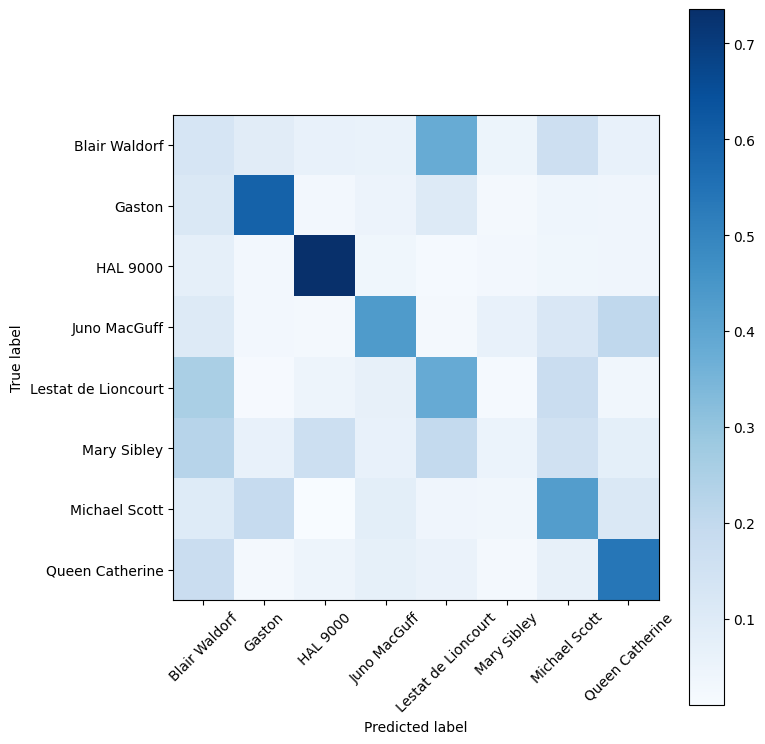

In [6]:
name = "Instruction General Local (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general.csv"

process_dataset(name=name, path=path, options="local")


Processing: Instruction General All (Original)


Inferencing Instruction General All (Original):   0%|          | 0/23730 [00:00<?, ?it/s]


Overall Accuracy: 18.25%


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,2980,1903,208,1077,0.901468,0.638591,0.747594
1,Gaston,2970,1452,53,1518,0.964784,0.488889,0.648939
2,Michael Scott,3000,582,119,2418,0.830243,0.194000,0.314510
3,Juno MacGuff,2950,260,72,2690,0.783133,0.088136,0.158440
4,Queen Catherine,2940,58,8,2882,0.878788,0.019728,0.038589
5,Lestat de Lioncourt,2930,48,0,2882,1.000000,0.016382,0.032236
6,Blair Waldorf,2980,17,0,2963,1.000000,0.005705,0.011345
7,Mary Sibley,2980,11,0,2969,1.000000,0.003691,0.007355


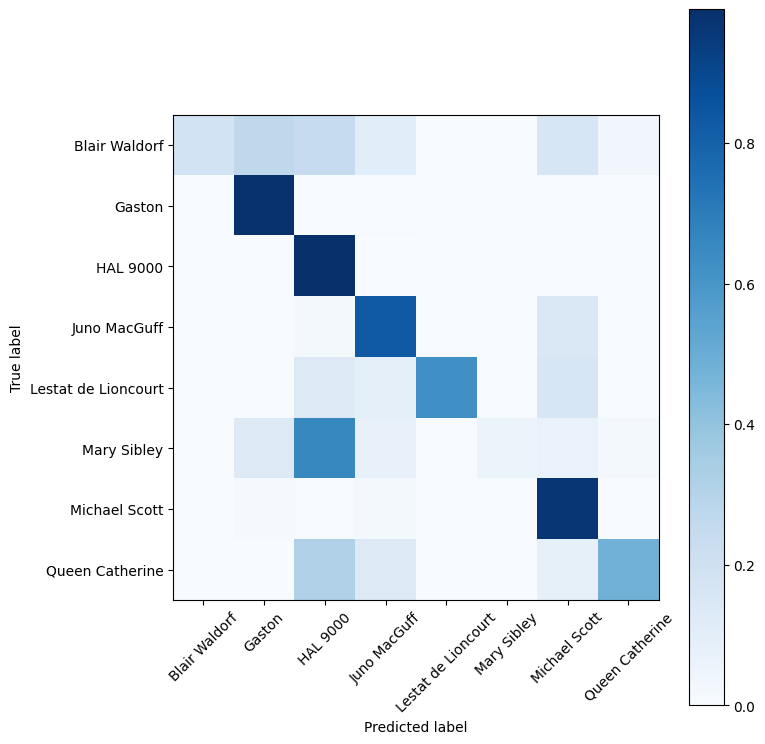

In [7]:
name = "Instruction General All (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general.csv"

process_dataset(name=name, path=path, options="all")


Processing: Instruction General Local (0)


Inferencing Instruction General Local (0):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 60.85%


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,297,293,82,4,0.781333,0.986532,0.872024
1,Queen Catherine,294,273,124,21,0.687657,0.928571,0.790159
2,HAL 9000,298,255,5,43,0.980769,0.855705,0.913978
3,Michael Scott,300,228,164,72,0.581633,0.760000,0.658960
4,Lestat de Lioncourt,293,200,303,93,0.397614,0.682594,0.502513
5,Juno MacGuff,295,161,18,134,0.899441,0.545763,0.679325
6,Mary Sibley,298,23,42,275,0.353846,0.077181,0.126722
7,Blair Waldorf,298,11,191,287,0.054455,0.036913,0.044000


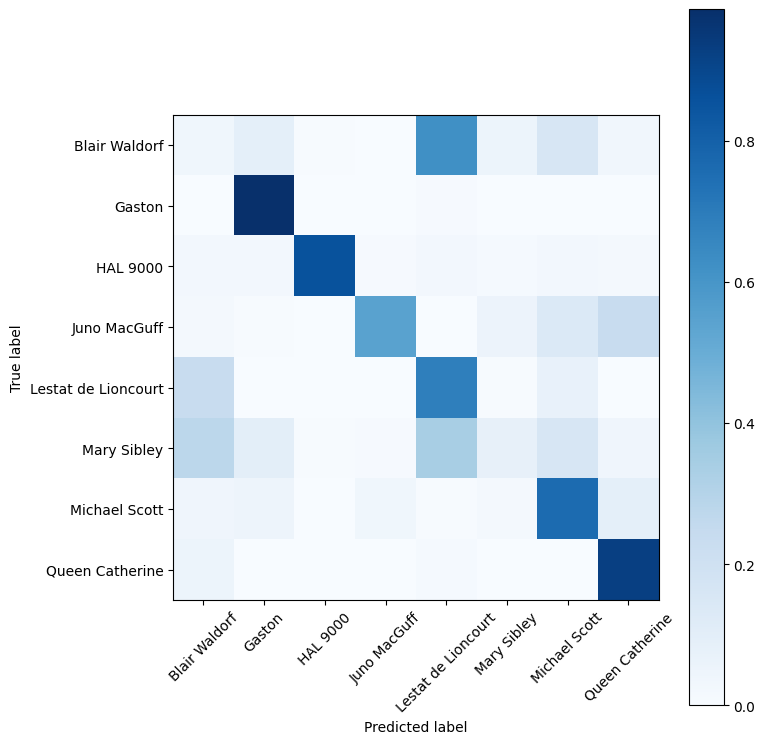

In [8]:
name = "Instruction General Local (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_0.csv"

process_dataset(name=name, path=path, options="local")


Processing: Instruction General All (0)


Inferencing Instruction General All (0):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 33.97%


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,297,287,21,10,0.931818,0.966330,0.948760
1,HAL 9000,298,213,0,85,1.000000,0.714765,0.833659
2,Michael Scott,300,170,4,130,0.977011,0.566667,0.717300
3,Juno MacGuff,295,88,3,207,0.967033,0.298305,0.455959
4,Queen Catherine,294,27,3,267,0.900000,0.091837,0.166667
5,Lestat de Lioncourt,293,11,0,282,1.000000,0.037543,0.072368
6,Mary Sibley,298,8,0,290,1.000000,0.026846,0.052288
7,Blair Waldorf,298,2,0,296,1.000000,0.006711,0.013333


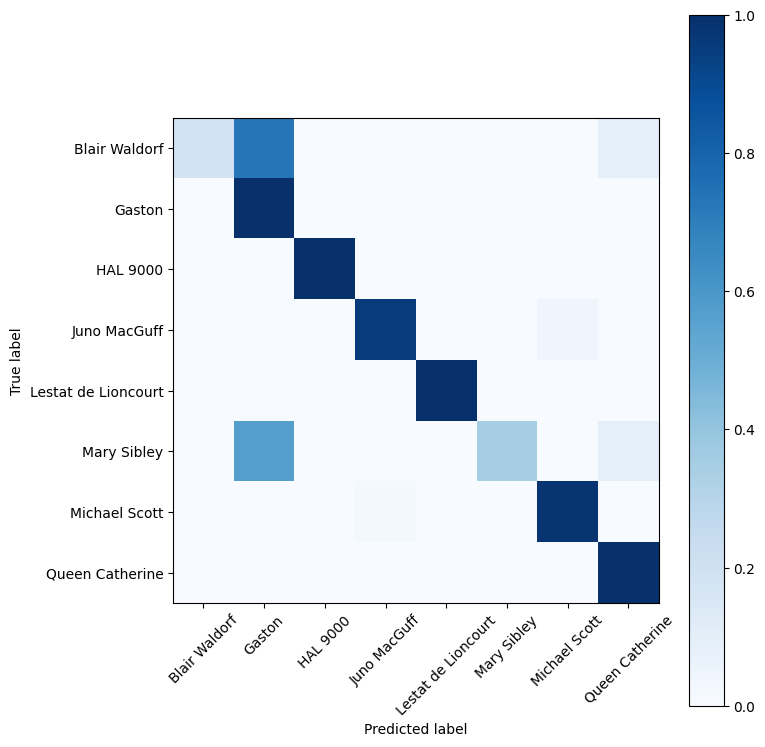

In [9]:
name = "Instruction General All (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_0.csv"

process_dataset(name=name, path=path, options="all")


Processing: Instruction General Local (102)


Inferencing Instruction General Local (102):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 25.87%


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,298,152,188,146,0.447059,0.510067,0.476489
1,Juno MacGuff,295,112,387,183,0.224449,0.379661,0.282116
2,Michael Scott,300,101,272,199,0.270777,0.336667,0.300149
3,Gaston,297,97,175,200,0.356618,0.326599,0.340949
4,Blair Waldorf,298,52,340,246,0.132653,0.174497,0.150725
5,Queen Catherine,294,45,155,249,0.225000,0.153061,0.182186
6,Lestat de Lioncourt,293,38,153,255,0.198953,0.129693,0.157025
7,Mary Sibley,298,17,89,281,0.160377,0.057047,0.084158


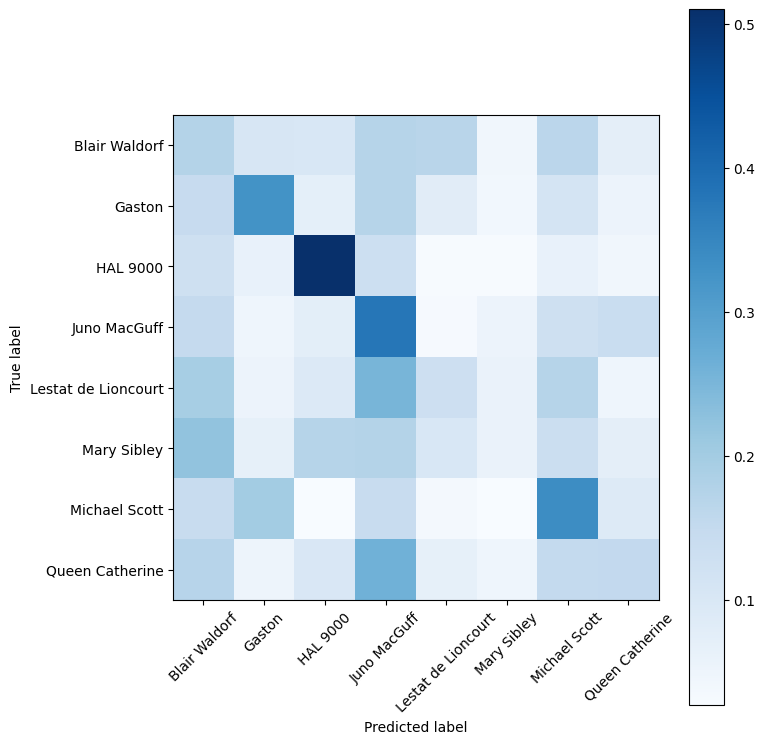

In [10]:
name = "Instruction General Local (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_102.csv"

process_dataset(name=name, path=path, options="local")


Processing: Instruction General All (102)


Inferencing Instruction General All (102):   0%|          | 0/2373 [00:00<?, ?it/s]


Overall Accuracy: 9.73%


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,298,115,31,183,0.787671,0.385906,0.518018
1,Gaston,297,73,0,224,1.000000,0.245791,0.394595
2,Michael Scott,300,26,17,274,0.604651,0.086667,0.151603
3,Juno MacGuff,295,11,28,284,0.282051,0.037288,0.065868
4,Queen Catherine,294,3,0,291,1.000000,0.010204,0.020202
5,Lestat de Lioncourt,293,2,0,291,1.000000,0.006826,0.013559
6,Blair Waldorf,298,1,0,297,1.000000,0.003356,0.006689
7,Mary Sibley,298,0,0,298,0.000000,0.000000,0.000000


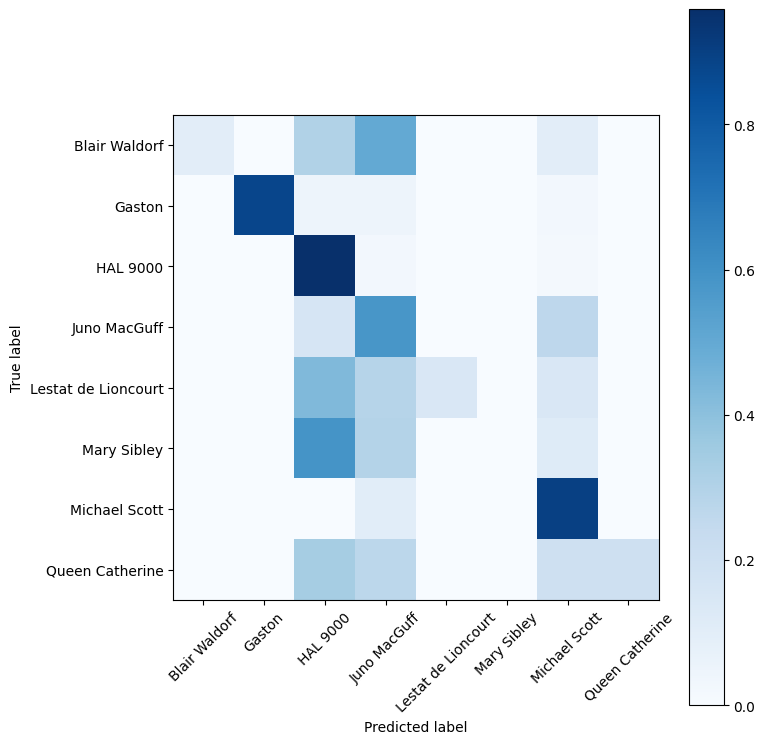

In [11]:
name = "Instruction General All (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_general_102.csv"

process_dataset(name=name, path=path, options="all")

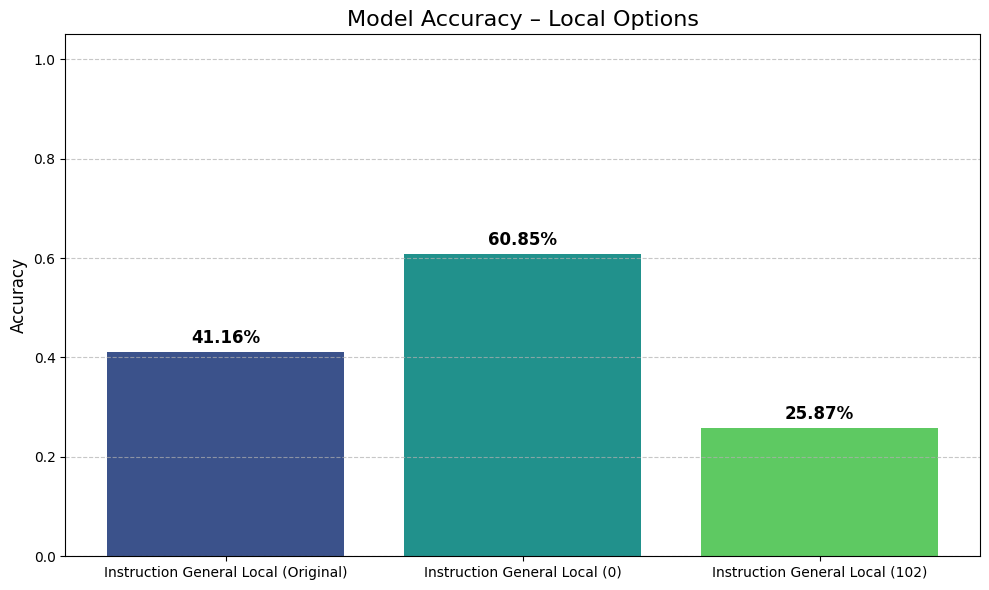

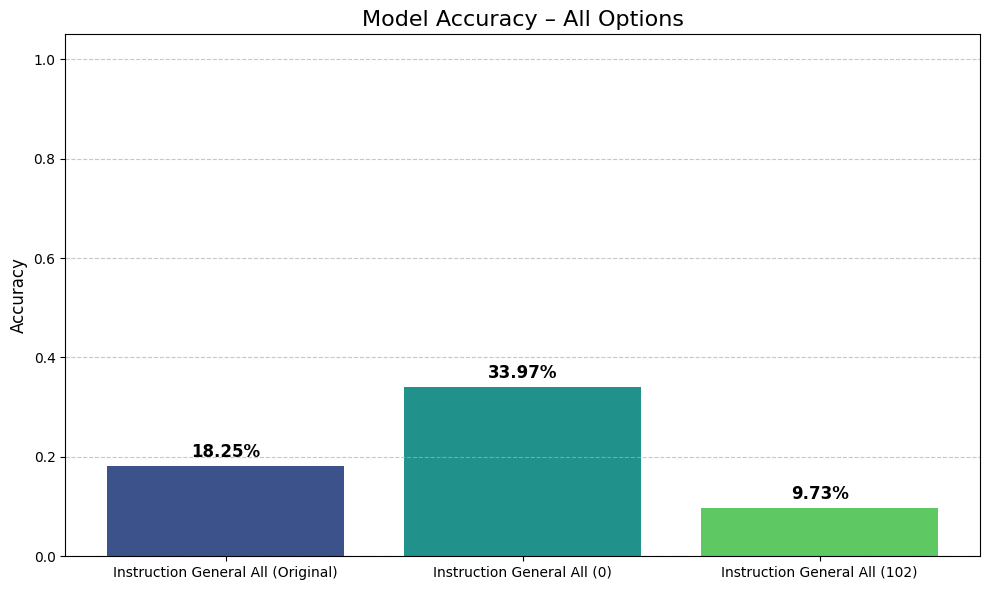

In [12]:
if GLOBAL_RESULTS:
    items = list(GLOBAL_RESULTS.items())

    even_items = items[::2]
    odd_items = items[1::2]

    def plot_results(items, title):
        names = [k for k, v in items]
        values = [v for k, v in items]
        colors = sns.color_palette("viridis", len(names))

        plt.figure(figsize=(10, 6))
        bars = plt.bar(names, values, color=colors)

        plt.title(title, fontsize=16)
        plt.ylabel("Accuracy", fontsize=12)
        plt.ylim(0, 1.05)
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        for bar in bars:
            height = bar.get_height()
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                height + 0.01,
                f'{height:.2%}',
                ha='center',
                va='bottom',
                fontsize=12,
                fontweight='bold'
            )

        plt.tight_layout()
        plt.show()

    plot_results(even_items, "Model Accuracy – Local Options")
    plot_results(odd_items, "Model Accuracy – All Options")